# 이진 분류 실험 ③ — 계좌 단기 활동 피처 추가 (account activity)
1단계 피처 사다리의 두 번째 칸. 02(기본 4 + port 2 + pair 4) 위에 **거래 직전 두 계좌의 활동량** 피처 8개를 더한다. 모델은 GINe 고정, 나머지 설정은 01·02 와 동일.

| 피처 | 뜻 (전부 그 거래 시각 기준 과거, 같은 분 제외) |
|---|---|
| `src_out_1h` / `src_out_1d` | 송신 계좌가 최근 60분 / 24시간 안에 보낸 거래 수 |
| `src_uniq_dst_1d` | 송신 계좌가 최근 24시간 안에 보낸 **상대 계좌 수** (일 단위 첫 거래 수로 근사) |
| `src_out_amt_1d` | 송신 계좌가 최근 24시간 안에 보낸 금액 합 |
| `dst_in_1h` / `dst_in_1d` | 수신 계좌가 최근 60분 / 24시간 안에 받은 거래 수 |
| `dst_uniq_src_1d` | 수신 계좌가 최근 24시간 안에 받은 **상대 계좌 수** |
| `dst_in_amt_1d` | 수신 계좌가 최근 24시간 안에 받은 금액 합 |

전부 `ln(1 + x)`. 창은 1h(버스트)와 1d(하루 활동) 두 개 — GFP 논문도 fan/degree 를 시간 창으로 센다 (`sampling/reference.md` 6절).

**가설**: 한 계좌가 짧은 시간에 여러 상대와 거래하는 **FAN-OUT / FAN-IN**, 모았다 뿌리는 **GATHER-SCATTER / SCATTER-GATHER** 의 recall 이 빡빡한 컷(0.1%, argmax)에서 오른다.
02 에서 가장 약했던 **고차수 수신자 [20-49]·[50-99] 구간**의 AP 가 오르는지도 본다 (`dst_in_1d` 가 "지금 이 계좌가 허브인가" 를 직접 말해 줌).

**메모리** (02 에서 두 번 죽고 고친 것): ① 피처 parquet 은 tx 올리기 전에 만든다 (DuckDB 12GB + tx 10GB 면 한도 초과) ② 피처 열은 float16 으로 붙이고 z-norm 결과도 float16 ③ 피처 행렬은 memmap 으로 두어 RSS 에서 뺀다. 셀마다 `B.trim` 으로 RSS 를 찍는다.

**누수 규칙**: 02 와 같음 — 거래 시각 기준 과거만, 같은 분 제외, z-norm 은 학습 구간 통계. 공통 코드 `bc_lib.py`

# 공통 부분 (작업 준비, 데이터 준비)

## 0. 작업 준비

In [1]:
import sys, json, time, gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

sys.path.append(str(Path.cwd()))
import bc_lib as B
L = B.L

In [2]:
# ---- 실험 설정 ------------------------------------------------------------
RUN_NAME = 'account_activity'     # results/<DATASET>/account_activity/
PREV_RUN = 'pair_history'         # 비교 기준 (02)
cfg = B.Config(dataset='HI-Large', smoke=False)
B.seed_all(cfg.seed)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT_DIR = cfg.out_dir(RUN_NAME)

# 앞 단계 피처 (02 에서 만든 parquet 재사용) + 이번 단계 피처
PAIR_FEATURES = ['pair_prior_count', 'pair_gap_minutes', 'pair_count_1h', 'reverse_history_count']
PAIR_PATH = cfg.feat_dir / 'pair_history.parquet'
STAGE_FEATURES = ['src_out_1h', 'src_out_1d', 'src_uniq_dst_1d', 'src_out_amt_1d', 'dst_in_1h', 'dst_in_1d', 'dst_uniq_src_1d', 'dst_in_amt_1d']
STAGE_PATH = cfg.feat_dir / 'account_activity.parquet'
GNN_EDGE_FEATURES = B.BASIC_EDGE_FEATURES + B.PORT_FEATURES + PAIR_FEATURES + STAGE_FEATURES   # FEAT16 열 순서. port 는 4,5 번
TREE_FEATURES = B.BASIC_EDGE_FEATURES + PAIR_FEATURES + STAGE_FEATURES                         # 트리는 port 없이
assert PAIR_PATH.exists(), '02 를 먼저 돌려 pair_history.parquet 을 만들어야 한다'
DEVICE, OUT_DIR, len(GNN_EDGE_FEATURES), len(TREE_FEATURES)

(device(type='cuda'),
 PosixPath('/workspace/money_laundry_ai_/code/binary_classification/results/HI-Large/account_activity'),
 18,
 16)

In [3]:
cfg

Config(dataset='HI-Large', smoke=False, val_neg_rate=0.02, scale_pos_weight=6, tree_rounds=500, tree_early_stop=20, num_neighbors=[100, 100], batch_size=2048, iter_per_epoch=256, epochs=400, eval_period=4, patience=8, class_weight=[1.0, 6.27], n_hidden=66, n_gnn_layers=2, lr=0.006, dropout=0.01, final_dropout=0.1, num_workers=0, seed=42)

## 1. 이번 단계 피처 계산 — 계좌 단기 활동 (tx 를 올리기 **전에**)
DuckDB 창 함수가 메모리 한도(12GB)까지 쓴다. 1.8억 건 `tx`(15열, 약 10GB)를 먼저 올려 두면 둘이 합쳐 25GB 를 넘겨 커널이 죽는다 → 피처 parquet 을 먼저 만들고 그 다음 tx 를 올린다 (한 번 만들면 이 절은 바로 지나간다)

- DuckDB 창 함수 두 번: **송신 계좌(src) 파티션** 한 번, **수신 계좌(dst) 파티션** 한 번. 02 의 pair 창과 같은 꼴 (`RANGE … PRECEDING AND INTERVAL '1 minute' PRECEDING`)
- 상대 계좌 수(`uniq_*_1d`): 창 함수로 `count(DISTINCT)` 를 1.8억 건에 돌리면 무거워서, **(계좌, 상대, 일) 의 첫 거래에 1 을 찍고 24시간 창에서 합산**으로 근사. 같은 상대가 어제 밤·오늘 아침 둘 다 있으면 2로 세는 오차가 있지만 방향은 같다
- 금액은 `received`(Amount Received, 기본 피처와 같은 열) 의 창 합계
- 결과는 `features_bc/account_activity.parquet` (edge_id 순). 한 번 만들면 재사용. pandas 를 거치지 않는다

In [4]:
con = L.connect(threads=8, memory='12GB')
currency_codes, format_codes = B.code_tables(con, cfg)
PORTS_PATH = B.ensure_ports(con, cfg)               # 있으면 건너뜀

In [5]:
# 이전 실행이 COPY 도중 죽었으면 불완전한 parquet 이 남아 있을 수 있다 → 행 수가 tx 와 다르면 지우고 다시 만든다
if STAGE_PATH.exists():
    n_stage = con.execute(f"SELECT count(*) FROM read_parquet({L.q(STAGE_PATH)})").fetchone()[0]
    n_tx = con.execute(f"SELECT count(*) FROM read_parquet({L.q(cfg.tx_path)})").fetchone()[0]
    if n_stage != n_tx:
        print(f'불완전한 {STAGE_PATH.name} ({n_stage:,} / {n_tx:,} 행) → 삭제 후 재생성'); STAGE_PATH.unlink()
if not STAGE_PATH.exists():
    t0 = time.time()
    con.execute(f"""
        CREATE OR REPLACE TABLE tx_min AS
        SELECT edge_id, src, dst, ts, day, received FROM read_parquet({L.q(cfg.tx_path)})""")
    # (a) 송신 계좌 기준 — 같은 src 의 과거 보낸 거래. first_pair_day = (src, dst, 일) 안의 첫 거래 표시 (상대 수 근사용)
    con.execute("""
        CREATE OR REPLACE TABLE src_win AS
        SELECT edge_id,
               count(*)            OVER w1h AS out_1h,
               count(*)            OVER w1d AS out_1d,
               sum(first_pair_day) OVER w1d AS uniq_dst_1d,
               sum(received)       OVER w1d AS out_amt_1d
        FROM (SELECT *, CASE WHEN row_number() OVER (PARTITION BY src, dst, day ORDER BY ts, edge_id) = 1 THEN 1 ELSE 0 END AS first_pair_day FROM tx_min)
        WINDOW w1h AS (PARTITION BY src ORDER BY ts RANGE BETWEEN INTERVAL '60 minutes' PRECEDING AND INTERVAL '1 minute' PRECEDING),
               w1d AS (PARTITION BY src ORDER BY ts RANGE BETWEEN INTERVAL '24 hours'  PRECEDING AND INTERVAL '1 minute' PRECEDING)""")
    print(f'  src_win {time.time()-t0:.0f}s')
    # (b) 수신 계좌 기준 — 같은 dst 의 과거 받은 거래
    con.execute("""
        CREATE OR REPLACE TABLE dst_win AS
        SELECT edge_id,
               count(*)            OVER w1h AS in_1h,
               count(*)            OVER w1d AS in_1d,
               sum(first_pair_day) OVER w1d AS uniq_src_1d,
               sum(received)       OVER w1d AS in_amt_1d
        FROM (SELECT *, CASE WHEN row_number() OVER (PARTITION BY dst, src, day ORDER BY ts, edge_id) = 1 THEN 1 ELSE 0 END AS first_pair_day FROM tx_min)
        WINDOW w1h AS (PARTITION BY dst ORDER BY ts RANGE BETWEEN INTERVAL '60 minutes' PRECEDING AND INTERVAL '1 minute' PRECEDING),
               w1d AS (PARTITION BY dst ORDER BY ts RANGE BETWEEN INTERVAL '24 hours'  PRECEDING AND INTERVAL '1 minute' PRECEDING)""")
    print(f'  dst_win {time.time()-t0:.0f}s')
    # (c) ln 변환 후 저장 (edge_id 순)
    con.execute(f"""
        COPY (
            SELECT t.edge_id,
                   ln(1 + s.out_1h)::FLOAT                   AS src_out_1h,
                   ln(1 + s.out_1d)::FLOAT                   AS src_out_1d,
                   ln(1 + coalesce(s.uniq_dst_1d, 0))::FLOAT AS src_uniq_dst_1d,
                   ln(1 + coalesce(s.out_amt_1d, 0))::FLOAT  AS src_out_amt_1d,
                   ln(1 + d.in_1h)::FLOAT                    AS dst_in_1h,
                   ln(1 + d.in_1d)::FLOAT                    AS dst_in_1d,
                   ln(1 + coalesce(d.uniq_src_1d, 0))::FLOAT AS dst_uniq_src_1d,
                   ln(1 + coalesce(d.in_amt_1d, 0))::FLOAT   AS dst_in_amt_1d
            FROM tx_min t JOIN src_win s USING (edge_id) JOIN dst_win d USING (edge_id)
            ORDER BY t.edge_id
        ) TO {L.q(STAGE_PATH)} (FORMAT PARQUET, COMPRESSION ZSTD)""")
    con.execute("DROP TABLE src_win; DROP TABLE dst_win; DROP TABLE tx_min")
    print(f'{STAGE_PATH.name} 생성 {time.time()-t0:.0f}s')
con.execute(f"SELECT count(*), {', '.join(f'avg({c}) AS avg_{c}' for c in STAGE_FEATURES)} FROM read_parquet({L.q(STAGE_PATH)})").df().T

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,0
count_star(),1.797021e+08
avg_src_out_1h,1.063768e+00
avg_src_out_1d,2.236039e+00
avg_src_uniq_dst_1d,1.825606e+00
avg_src_out_amt_1d,9.582797e+00
avg_dst_in_1h,4.394570e-01
avg_dst_in_1d,1.075625e+00
avg_dst_uniq_src_1d,7.866559e-01
avg_dst_in_amt_1d,7.244756e+00


In [6]:
# 창 동작 확인 — 하루에 거래 8건쯤 보낸 계좌 하나를 골라 그 계좌의 보낸 거래 타임라인 (out_1h 는 1시간 지나면 줄고, out_1d 는 하루 안에서 1씩 늘고, uniq 는 새 상대일 때만 느는지)
# 주의: 1.8억 건끼리 조인하지 않는다 → 그 계좌의 edge_id 만 골라 피처 parquet 에서 읽는다
acct = con.execute(f"SELECT src FROM read_parquet({L.q(cfg.tx_path)}) GROUP BY src, day ORDER BY abs(count(*) - 8), src LIMIT 1").fetchone()[0]
ids = con.execute(f"SELECT edge_id, ts, dst, received FROM read_parquet({L.q(cfg.tx_path)}) WHERE src = {acct} ORDER BY ts LIMIT 40").df()
feat = con.execute(f"SELECT edge_id, src_out_1h, src_out_1d, src_uniq_dst_1d, src_out_amt_1d FROM read_parquet({L.q(STAGE_PATH)}) WHERE edge_id IN ({', '.join(map(str, ids.edge_id))})").df()
tl = ids.merge(feat, on='edge_id').sort_values('ts')
for c in ['src_out_1h', 'src_out_1d', 'src_uniq_dst_1d']:
    tl[c.replace('src_', '') + ' (건수)'] = np.expm1(tl[c]).round(0).astype(int)      # ln(1+x) 를 되돌려 건수로
tl

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,edge_id,ts,dst,received,src_out_1h,src_out_1d,src_uniq_dst_1d,src_out_amt_1d,out_1h (건수),out_1d (건수),uniq_dst_1d (건수)
0,130498,2022-08-01 00:03:00,0,11.21,0.000000,0.000000,0.000000,0.000000,0,0,0
1,1736297,2022-08-01 03:39:00,86029,521.90,0.000000,0.693147,0.693147,2.502255,0,1,1
2,1760854,2022-08-01 03:50:00,86029,564.35,0.693147,1.098612,1.098612,6.280602,1,2,2
3,2130513,2022-08-01 06:36:00,65675,1847.03,0.000000,1.386294,1.098612,7.001665,0,3,2
4,2179612,2022-08-01 06:58:00,65675,2285.52,0.693147,1.609438,1.386294,7.988030,1,4,3
5,3559332,2022-08-01 17:15:00,0,1259.35,0.000000,1.791759,1.386294,8.562360,0,5,3
6,3785254,2022-08-01 18:56:00,29873,1127.66,0.000000,1.945910,1.386294,8.778073,0,6,3
7,4269502,2022-08-01 22:32:00,0,65.15,0.000000,2.079442,1.609438,8.938272,0,7,4
8,4296345,2022-08-01 22:44:00,0,579.25,0.693147,2.197225,1.609438,8.946788,1,8,4
9,4750022,2022-08-02 02:52:00,29873,1127.66,0.000000,2.197225,1.386294,9.018115,0,8,3


## 2. 데이터 준비 — 거래 전체 + port + pair(02) + 이번 피처
전부 edge_id 순 parquet 이라 조인 없이 열만 붙인다 (`attach_parquet`)

In [7]:
con.close(); con = L.connect(threads=8, memory='3GB')      # 창 함수가 잡아 둔 DuckDB 버퍼 반납. 이후 쿼리는 작아서 3GB 면 충분
con.register('currency_codes', currency_codes); con.register('format_codes', format_codes)   # 코드표는 연결마다 다시 등록
tx = B.load_tx_lowmem(con, cfg, port_path=PORTS_PATH)                      # 기본 9열 + port 2열 — parquet 에서 열 하나씩 (DuckDB .df() 피크 회피)
B.trim('(tx 기본+port 적재 후)')
tx = B.attach_parquet(tx, PAIR_PATH, PAIR_FEATURES, dtype=np.float16)     # 02 의 pair 피처 — float16 (ln 값이라 충분)
tx = B.attach_parquet(tx, STAGE_PATH, STAGE_FEATURES, dtype=np.float16)   # 이번 피처
B.trim('(피처 12열 붙인 후)'); tx.shape

RSS 9.6 GB (tx 기본+port 적재 후)
RSS 14.2 GB (피처 12열 붙인 후)


(179702079, 23)

In [8]:
tx.head()

/usr/local/lib/python3.12/dist-packages/pandas/io/formats/format.py:1466: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,edge_id,src,dst,day,timestamp,amount_received,received_currency,payment_format,y,in_port,...,pair_count_1h,reverse_history_count,src_out_1h,src_out_1d,src_uniq_dst_1d,src_out_amt_1d,dst_in_1h,dst_in_1d,dst_uniq_src_1d,dst_in_amt_1d
0,1,3,3,2022-08-01,0.0,19.180000,12,5,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2,25,78803,2022-08-01,0.0,17955.109375,12,3,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3,31,86028,2022-08-01,0.0,1199.829956,12,2,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4,39,269980,2022-08-01,0.0,148565.453125,12,6,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,5,50,29866,2022-08-01,0.0,227247.421875,12,3,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [9]:
tx[STAGE_FEATURES].describe().T

/usr/local/lib/python3.12/dist-packages/pandas/core/nanops.py:1524: RuntimeWarning: overflow encountered in cast
  return dtype.type(n)
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:49: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
/usr/local/lib/python3.12/dist-packages/pandas/core/nanops.py:725: RuntimeWarning: invalid value encountered in scalar divide
  the_mean = the_sum / count if count > 0 else np.nan
/usr/local/lib/python3.12/dist-packages/pandas/core/nanops.py:1524: RuntimeWarning: overflow encountered in cast
  return dtype.type(n)
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:49: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
/usr/local/lib/python3.12/dist-packages/pandas/core/nanops.py:725: RuntimeWarning: invalid value encountered in scalar divide
  the_mean = the_sum / count if count > 0 else np.nan
/usr/local

,count,mean,std,min,25%,50%,75%,max
src_out_1h,179702079.0,NaN,0.0,0.0,0.000000,0.693359,1.098633,9.921875
src_out_1d,179702079.0,NaN,0.0,0.0,0.693359,1.609375,2.302734,11.687500
src_uniq_dst_1d,179702079.0,NaN,0.0,0.0,0.693359,1.098633,1.609375,10.929688
src_out_amt_1d,179702079.0,NaN,0.0,0.0,6.183594,9.414062,12.632812,30.875000
dst_in_1h,179702079.0,NaN,0.0,0.0,0.000000,0.000000,0.693359,4.875000
dst_in_1d,179702079.0,NaN,0.0,0.0,0.693359,1.098633,1.609375,7.742188
dst_uniq_src_1d,179702079.0,NaN,0.0,0.0,0.693359,0.693359,1.098633,7.742188
dst_in_amt_1d,179702079.0,NaN,0.0,0.0,4.632812,7.871094,10.320312,30.187500


In [10]:
# 라벨별 평균 — 세탁 거래에서 값이 다른가 (피처가 신호를 갖는지 미리 확인). pandas groupby 는 열 단위라 가볍다
tx.groupby('y')[STAGE_FEATURES].mean().T.rename(columns={0: 'normal', 1: 'laundering'})

y,normal,laundering
src_out_1h,1.064207,0.776982
src_out_1d,2.236996,1.593625
src_uniq_dst_1d,1.826310,1.378656
src_out_amt_1d,9.587427,5.898304
dst_in_1h,0.439792,0.244257
dst_in_1d,1.076208,0.739540
dst_uniq_src_1d,0.787036,0.587356
dst_in_amt_1d,7.247368,5.165527


## 3. z-norm (학습 구간 통계) + 표본

In [11]:
in_train = B.window_mask(tx, cfg.train_window)
FEAT_PATH = cfg.feat_dir / f'feat16_{RUN_NAME}.npy'                       # z-norm 행렬을 디스크 memmap 으로 (18열 6.5GB 가 RSS 에서 빠짐)
feat_z, znorm_table = B.znorm_features(tx, GNN_EDGE_FEATURES, in_train, out_path=FEAT_PATH)   # tx 에서 피처 열은 떨어짐
B.trim('(z-norm 후)'); znorm_table

RSS 6.5 GB (z-norm 후)


,feature,mean(train),std(train)
0,timestamp,3.036519e+06,1.403026e+06
1,amount_received,5.573174e+06,1.804616e+09
2,received_currency,8.450158e+00,4.231340e+00
3,payment_format,2.946519e+00,1.430707e+00
4,in_port,1.691504e+00,2.026216e+01
5,out_port,1.258211e+03,5.523149e+03
6,pair_prior_count,3.619805e+00,1.249467e+00
7,pair_gap_minutes,4.934153e+00,3.020589e+00
8,pair_count_1h,3.837265e-01,4.403188e-01
9,reverse_history_count,1.201983e-01,5.942292e-01


In [12]:
print(f"데이터 기간 {tx['day'].min().date()} ~ {tx['day'].max().date()}")
for name, w in [('train', cfg.train_window), ('val', cfg.val_window), ('test', cfg.test_window)]:
    m = B.window_mask(tx, w); assert m.sum() > 0, f'{name} 구간 {w} 에 거래가 없음'
    print(f'{name:5s} {w}  거래 {m.sum():>12,}  세탁 {tx.loc[m, "y"].sum():>8,}  비율 {tx.loc[m, "y"].mean()*100:.3f}%')

데이터 기간 2022-08-01 ~ 2023-01-12
train 2022-08-08:2022-10-02  거래  102,336,629  세탁  110,671  비율 0.108%
val   2022-10-03:2022-10-16  거래   24,413,046  세탁   33,795  비율 0.138%
test  2022-10-17:2022-10-30  거래   26,808,230  세탁   34,460  비율 0.129%


In [13]:
val_df = B.val_sample(con, cfg.val_window, cfg.val_neg_rate)        # 검증: 가중 표본 (05 공유)
test_df = B.test_full(con, cfg.test_window)                         # 테스트: 구간 전체
in_degree = B.recipient_indegree(con, cfg)                           # 분석용
con.close()

all_edge_ids = tx['edge_id'].to_numpy()
val_idx = B.rows_of(all_edge_ids, val_df['edge_id'].to_numpy()); test_idx = B.rows_of(all_edge_ids, test_df['edge_id'].to_numpy())
assert (tx['y'].to_numpy()[val_idx] == val_df['y'].to_numpy()).all()
del all_edge_ids
val_df.shape, test_df.shape

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

((521382, 7), (26808230, 5))

# 트리 모델 (기본 4 + pair 4 + 이번 피처 8)

## 4. LightGBM / XGBoost

In [14]:
results = {}
tree_cols = [GNN_EDGE_FEATURES.index(c) for c in TREE_FEATURES]
train_mask = in_train; train_rows = np.flatnonzero(train_mask)
# 행 묶음으로 바로 float32 행렬에 채운다 — feat_z[mask][:, cols].astype() 은 중간 배열 3개(13GB)가 생겨 RSS 27GB 로 죽었다
X_train = B.rows_matrix(feat_z, train_rows, tree_cols); y_train = tx['y'].to_numpy()[train_mask]
X_val, y_val, w_val = B.rows_matrix(feat_z, val_idx, tree_cols), val_df['y'].to_numpy(), val_df['w'].to_numpy()
test_pred = lambda m: B.predict_rows(m, feat_z, test_idx, tree_cols)     # 테스트 행렬(1.7GB)은 안 만들고 묶음 예측
if cfg.smoke:
    keep = np.random.default_rng(cfg.seed).choice(len(X_train), min(len(X_train), 200_000), replace=False)
    X_train, y_train = X_train[keep], y_train[keep]
B.trim('(트리 입력 준비 후)'); X_train.shape, X_train.dtype

RSS 15.4 GB (트리 입력 준비 후)


((102336629, 16), dtype('float32'))

In [15]:
lgb_model, xgb_model = B.train_trees(X_train, y_train, X_val, y_val, w_val, test_pred, val_df, test_df, cfg, results)
pd.DataFrame({'feature': TREE_FEATURES, 'lightgbm_gain': lgb_model.booster_.feature_importance('gain'),
              'xgboost_gain': [xgb_model.get_booster().get_score(importance_type='gain').get(f'f{i}', 0.0) for i in range(len(TREE_FEATURES))]})

/usr/local/lib/python3.12/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[13:09:49] lightgbm val AP 0.5137
[13:30:59] xgboost  val AP 0.5180


,feature,lightgbm_gain,xgboost_gain
0,timestamp,8.985485e+05,149.189484
1,amount_received,2.348895e+06,814.972046
2,received_currency,1.174223e+06,345.740723
3,payment_format,6.280144e+06,5392.464844
4,pair_prior_count,1.642592e+06,3204.529785
5,pair_gap_minutes,1.651098e+06,188.100342
6,pair_count_1h,3.455380e+05,775.906799
7,reverse_history_count,1.479902e+06,478.617981
8,src_out_1h,4.833123e+05,652.949036
9,src_out_1d,1.370736e+06,445.269653


In [16]:
# 트리 테스트 점수도 저장 (분석용) — 묶음 예측
for name, model in [('lightgbm', lgb_model), ('xgboost', xgb_model)]:
    pd.DataFrame(dict(edge_id=test_df.edge_id, y=test_df.y, score=test_pred(model))).to_parquet(OUT_DIR / f'{name}_test_scores.parquet', index=False)
del X_train, y_train, X_val; B.trim('(트리 입력 삭제 후)')
pd.DataFrame({k: v['val'] for k, v in results.items()}).T.round(4)

RSS 8.9 GB (트리 입력 삭제 후)


,AP,F1,precision,recall,threshold,recall_at_1pct,unmatched_recall_at_1pct,ECE,F1_at_0.5
lightgbm,0.5137,0.5543,0.7178,0.4515,0.6791,0.7707,0.4463,0.0039,0.5273
xgboost,0.5180,0.5635,0.7181,0.4637,0.6940,0.7620,0.4219,0.0045,0.5067


# GNN (GINe, 01 과 같은 설정)

## 5. 그래프 — 한 번에 하나만 (bc_lib.GraphStore)

In [17]:
# feat_z 가 이미 memmap 이라 GraphStore 는 그대로 쓴다. 02 는 이 시점 RSS 약 13GB, 학습 중 20.7GB 였다 — 여기선 피처 행렬이 빠져 더 작아야 정상
store = B.GraphStore(tx, feat_z, cfg, train_rows=np.flatnonzero(train_mask), val_idx=val_idx, test_idx=test_idx,
                     port_cols=[GNN_EDGE_FEATURES.index('in_port'), GNN_EDGE_FEATURES.index('out_port')])
del tx, feat_z; B.trim('(tx, feat_z 삭제 후)')
store.edge_dim

[13:36:30] 피처 행렬 memmap(기존) (179702079, 18)
[13:36:30] 간선 수 (정방향): 학습까지 117,269,636  검증까지 141,682,682  테스트까지 168,490,912
RSS 6.9 GB (tx, feat_z 삭제 후)


18

In [18]:
# 배치 하나 꺼내서 모양 확인 — 2048 target 이 서브그래프 하나를 공유, 엣지 피처 18열
batch = next(iter(store.use('train')))
print('노드', batch['node'].num_nodes, ' to 간선', batch[B.TO].num_edges, ' rev_to 간선', batch[B.REV].num_edges,
      ' target', batch[B.TO].edge_label_index.shape[1], ' 양성', int(batch[B.TO].edge_label.sum()),
      ' x 열', batch['node'].x.shape[1], ' edge_attr 열', batch[B.TO].edge_attr.shape[1], ' target_attr', tuple(batch.target_attr.shape))

RSS 6.9 GB 
[13:37:13] 그래프 to 117,269,636 + rev_to 117,269,636 간선 (정렬됨)  38s
RSS 16.5 GB 
노드 180175  to 간선 1638641  rev_to 간선 1529228  target 2048  양성 1  x 열 2  edge_attr 열 18  target_attr (2048, 18)


In [19]:
# 모델 모양 확인
model = B.make_gine(store.edge_dim, cfg, edge_updates=False).to(DEVICE)
logits, labels = B.forward_batch(model, batch, DEVICE)
print('파라미터', sum(p.numel() for p in model.parameters()), ' 로짓', tuple(logits.shape))
del model, batch

파라미터 67311  로짓 (2048, 2)


## 6. 학습 — GINe

In [20]:
gine_model, gine_hist = B.train_gnn('gine', store, cfg, val_df, OUT_DIR, DEVICE, edge_updates=False, results=results)
results['gine']['val']

gine epoch 1:   0%|          | 0/256 [00:00<?, ?it/s]

epoch   1  loss 0.0290  (386s)


gine epoch 2:   0%|          | 0/256 [00:00<?, ?it/s]

epoch   2  loss 0.0214  (371s)


gine epoch 3:   0%|          | 0/256 [00:00<?, ?it/s]

...

gine epoch 91:   0%|          | 0/256 [00:00<?, ?it/s]

epoch  91  loss 0.0148  (360s)


gine epoch 92:   0%|          | 0/256 [00:00<?, ?it/s]

RSS 12.8 GB 
[01:24:17] 그래프 to 141,682,682 + rev_to 141,682,682 간선 (정렬됨)  42s
RSS 18.7 GB 
epoch  92  loss 0.0139  AP 0.5403  F1 0.6171  F1@0.5 0.5945  recall@1% 0.7294  (750s)


{'AP': 0.5612747267274288,
 'F1': 0.6240993039174823,
 'F1_at_0.5': 0.6207417584734853,
 'precision': 0.7243628145337905,
 'recall': 0.5482171918922918,
 'threshold': 0.5296861529350281,
 'recall_at_1pct': 0.7588104749223258,
 'unmatched_recall_at_1pct': 0.41562614092734573,
 'ECE': 0.002103486415147137}

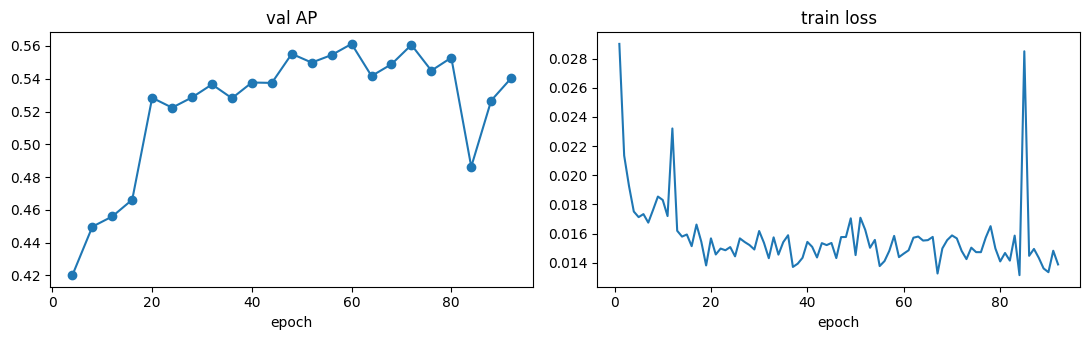

In [21]:
# 학습 곡선
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
hv = gine_hist.dropna(subset=['AP']); ax[0].plot(hv['epoch'], hv['AP'], marker='o'); ax[1].plot(gine_hist['epoch'], gine_hist['train_loss'])
ax[0].set_title('val AP'); ax[1].set_title('train loss'); ax[0].set_xlabel('epoch'); ax[1].set_xlabel('epoch')
plt.tight_layout(); plt.savefig(OUT_DIR / 'curves.png', dpi=120); plt.show()

## 7. 테스트 — 구간 전체

In [22]:
gine_score = B.test_gnn('gine', store, cfg, test_df, OUT_DIR, DEVICE, edge_updates=False, results=results)

RSS 12.8 GB 
[01:30:47] 그래프 to 168,490,912 + rev_to 168,490,912 간선 (정렬됨)  51s
RSS 21.0 GB 
gine (273분) {'AP': 0.5487, 'F1': 0.619, 'precision': 0.7505, 'recall': 0.5267, 'threshold': 0.7848, 'recall_at_1pct': 0.761, 'unmatched_recall_at_1pct': 0.4312, 'ECE': 0.0022, 'F1_at_0.5': 0.6069}


# 결과 — 저장된 점수 파일만으로 돌아간다
커널을 새로 켰으면 **0 절(설정 셀 3개)까지만** 돌리고 바로 여기부터. 재료는 `results/<DATASET>/<RUN_NAME>/`
- `{model}_test_scores.parquet` (edge_id, y, score) — 7 절·4 절에서 저장
- `results.json` — 검증/테스트 지표 (`results` dict 복구용)
- dst 와 수신자 in-degree 만 DuckDB 에서 다시 읽는다 (1~2 분)

운영점(컷)은 두 종류: **예산 컷** `r@b%` = 테스트 전체 상위 b% 를 알림으로 (0.05 / 0.1 / 0.5 / 1 / 2 / 5 / 10 % / all),
**argmax** = 확률 0.5 (논문 F1 운영점, Multi-GNN 부록 Table 13 의 패턴별 recall 과 같은 기준). 0.1% ≈ 양성 수 규모 ≈ argmax 와 비슷한 알림 수.

## 8. 준비 — 점수 · 라벨 · in-degree

In [23]:
import importlib; importlib.reload(B)
MODELS = [n for n in ['lightgbm', 'xgboost', 'gine'] if (OUT_DIR / f'{n}_test_scores.parquet').exists()]
scores = {n: B.load_scores(OUT_DIR / f'{n}_test_scores.parquet') for n in MODELS}
if 'test_df' not in globals() or 'in_degree' not in globals():
    con = L.connect(threads=8, memory='12GB')
    test_df = B.test_full(con, cfg.test_window); in_degree = B.recipient_indegree(con, cfg); con.close()
for n in MODELS:
    assert (scores[n]['edge_id'].to_numpy() == test_df['edge_id'].to_numpy()).all(), f'{n} 점수와 라벨 순서 불일치'
if 'results' not in globals() or not results:
    results = json.load(open(OUT_DIR / 'results.json'))['results']
print(MODELS, '| 테스트 간선', f"{len(test_df):,}", '| 양성', f"{int(test_df.y.sum()):,}", '| 컷', list(B.cut_thresholds(scores[MODELS[0]]['score'].to_numpy())))

['lightgbm', 'xgboost', 'gine'] | 테스트 간선 26,808,230 | 양성 34,460 | 컷 ['r@0.05%', 'r@0.1%', 'r@0.5%', 'r@1%', 'r@2%', 'r@5%', 'r@10%', 'all', 'argmax']


## 9. 운영점별 precision / recall
같은 점수를 컷만 바꿔 가며 본다. 예산을 줄이면 precision 이 오르고 recall 이 떨어지는 그 교환을 한 표에.

In [24]:
# 컷마다 임계값 · 알림 수 · TP/FP/FN · precision · recall (모델별). 'all' = 전부 알림 (precision = 양성 비율)
cut_df = pd.concat([B.cut_table(scores[n]).assign(model=n) for n in MODELS])
cut_df.to_csv(OUT_DIR / 'analysis_cuts.csv', encoding='utf-8-sig')
cut_df[cut_df.model == 'gine']

,threshold,alerts,TP,FP,FN,TN,precision,recall,model
cut,,,,,,,,,
r@0.05%,0.9947,13405,11694,1711,22766,26772059,0.8724,0.3393,gine
r@0.1%,0.6012,26809,18795,8014,15665,26765756,0.7011,0.5454,gine
r@0.5%,0.0768,134042,23372,110670,11088,26663100,0.1744,0.6782,gine
r@1%,0.0420,268083,26224,241859,8236,26531911,0.0978,0.7610,gine
r@2%,0.0254,681335,30072,651263,4388,26122507,0.0441,0.8727,gine
r@5%,0.0127,1340412,31391,1309021,3069,25464749,0.0234,0.9109,gine
r@10%,0.0102,2680828,33302,2647526,1158,24126244,0.0124,0.9664,gine
all,0.0000,26808230,34460,26773770,0,0,0.0013,1.0000,gine
argmax,0.5000,28397,19073,9324,15387,26764446,0.6717,0.5535,gine


In [25]:
# 모델 나란히 — 컷별 recall / precision
cut_df.reset_index().pivot(index='cut', columns='model', values=['recall', 'precision']).loc[cut_df.index.unique()]

recall                  precision                 
model      gine lightgbm xgboost      gine lightgbm xgboost
cut                                                        
r@0.05%  0.3393   0.3418  0.3429    0.8724   0.8787  0.8816
r@0.1%   0.5454   0.4943  0.4957    0.7011   0.6354  0.6371
r@0.5%   0.6782   0.6678  0.6652    0.1744   0.1717  0.1705
r@1%     0.7610   0.7656  0.7621    0.0978   0.0983  0.0980
r@2%     0.8727   0.8515  0.8432    0.0441   0.0547  0.0542
r@5%     0.9109   0.9105  0.9089    0.0234   0.0234  0.0234
r@10%    0.9664   0.9673  0.9664    0.0124   0.0124  0.0124
all      1.0000   1.0000  1.0000    0.0013   0.0013  0.0013
argmax   0.5535   0.5166  0.5290    0.6717   0.5635  0.5174

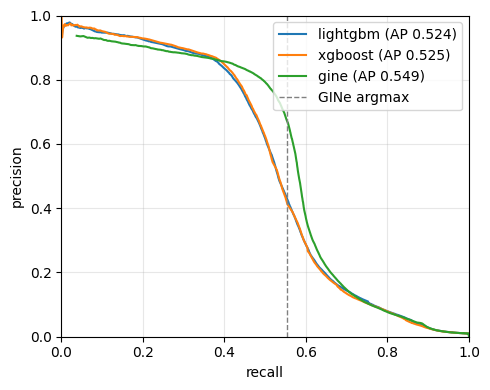

In [26]:
# PR 곡선 — 컷을 연속으로 훑은 것. AP = 곡선 아래 면적. 세로선 = GINe argmax 운영점
B.plot_pr(scores, path=OUT_DIR / 'pr_curve.png', mark=(cut_df.loc['argmax'].query("model == 'gine'")['recall'].iloc[0], 'GINe argmax'))

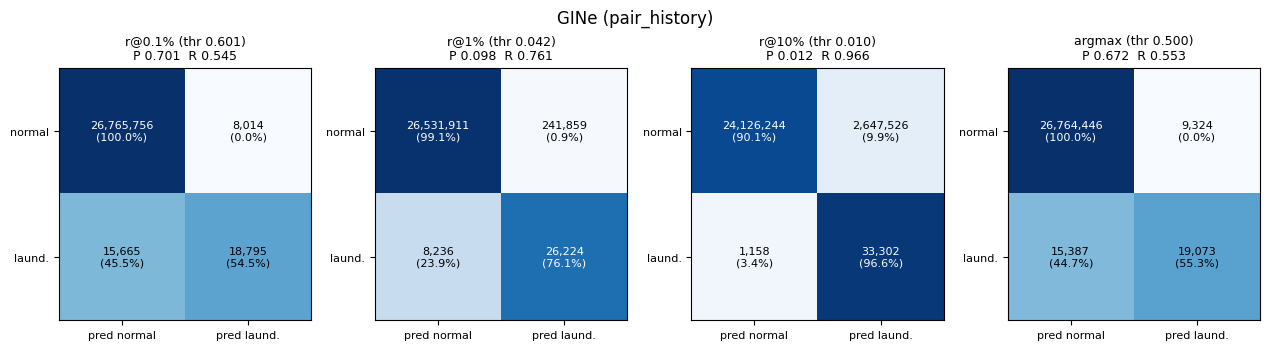

In [27]:
# 혼동행렬 — GINe, 컷 4개 나란히. 색 = 행 비율 (세탁 행 오른쪽 칸 = recall), 숫자 = 건수
B.plot_confusion_grid(scores['gine'], cuts=('r@0.1%', 'r@1%', 'r@10%', 'argmax'), title='GINe (pair_history)', path=OUT_DIR / 'confusion_cuts.png')

## 10. 패턴별 — 어느 패턴을 어느 컷에서 놓치나
패턴 안의 거래는 모두 양성이라 recall 만 본다. 예산을 줄일 때 먼저 떨어지는 패턴이 "모델이 덜 확신하는" 패턴.

In [28]:
# 패턴 × 컷 recall (모델별 저장, GINe 표시). 'recall' 열 = 1% (01 과 호환), mean_score = 그 패턴 양성의 평균 점수
pattern_df = pd.concat([B.pattern_recall(scores[n]).assign(model=n) for n in MODELS])
pattern_df.to_csv(OUT_DIR / 'analysis_pattern.csv', encoding='utf-8-sig')
CUT_COLS = [c for c in pattern_df.columns if c.startswith('r@') or c in ('all', 'argmax')]
pattern_df[pattern_df.model == 'gine'][['n'] + CUT_COLS + ['mean_score']]

,n,r@0.05%,r@0.1%,r@0.5%,r@1%,r@2%,r@5%,r@10%,all,argmax,mean_score
pattern_type,,,,,,,,,,,
FAN-OUT,2131,0.6762,0.9554,0.9897,0.9962,0.9986,1.0000,1.0000,1.0,0.9625,0.9517
FAN-IN,1922,0.5812,0.9324,0.9917,0.9964,0.9979,0.9995,0.9995,1.0,0.9459,0.9300
GATHER-SCATTER,3785,0.7152,0.9517,0.9884,0.9968,0.9984,0.9995,0.9997,1.0,0.9585,0.9504
SCATTER-GATHER,3891,0.7086,0.9548,0.9915,0.9961,0.9985,0.9992,0.9995,1.0,0.9630,0.9534
CYCLE,1853,0.4846,0.9045,0.9833,0.9897,0.9935,0.9984,0.9989,1.0,0.9174,0.8980
RANDOM,1335,0.4524,0.8959,0.9813,0.9918,0.9948,0.9978,0.9993,1.0,0.9139,0.8942
BIPARTITE,1833,0.4086,0.8609,0.9793,0.9929,0.9978,1.0000,1.0000,1.0,0.8783,0.8665
STACK,3437,0.4123,0.8886,0.9831,0.9904,0.9968,0.9983,0.9983,1.0,0.9078,0.8853
UNMATCHED,14273,0.0003,0.0102,0.2419,0.4312,0.6963,0.7862,0.9198,1.0,0.0125,0.0634


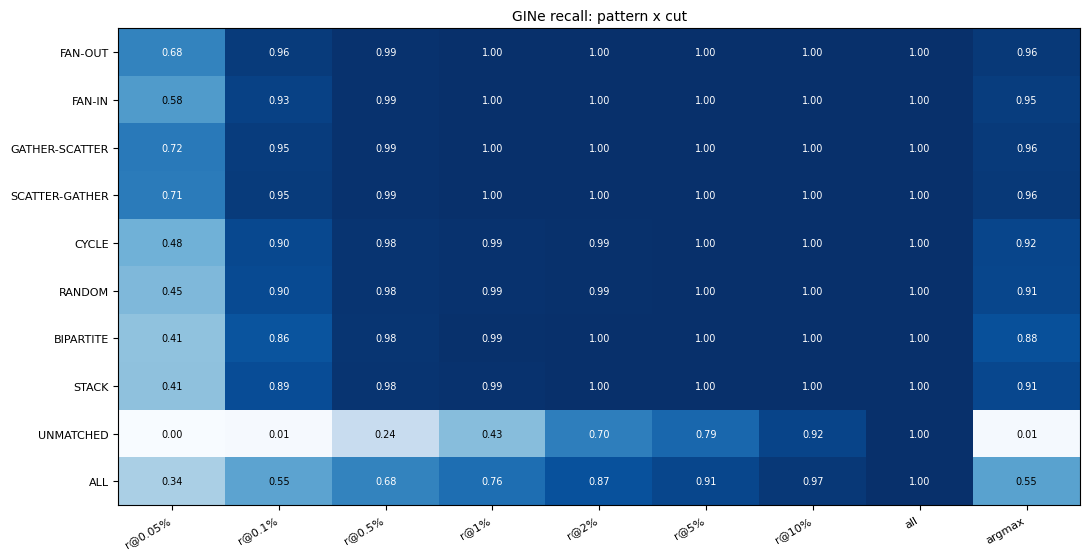

In [29]:
# 같은 표를 그림으로 — 행 = 패턴, 열 = 컷. 왼쪽(빡빡한 예산)에서 먼저 하얘지는 행이 약한 패턴
B.plot_heatmap(pattern_df[pattern_df.model == 'gine'][CUT_COLS], title='GINe recall: pattern x cut', path=OUT_DIR / 'pattern_x_cut.png')

In [30]:
# 놓친 세탁(FN) 의 구성 — 컷마다 FN 이 어느 패턴에서 나오나. FN% 가 pos_share 보다 크면 그 패턴을 유독 놓침
groups = dict(pattern=B.pattern_array(scores['gine']), degree_bin=B.degree_bin_of(test_df['dst'].to_numpy(), in_degree))
cb = B.confusion_breakdown(scores['gine'], groups)
for axis in groups:
    cb['fn'][axis].to_csv(OUT_DIR / f'analysis_fn_{axis}.csv', encoding='utf-8-sig'); cb['fp'][axis].to_csv(OUT_DIR / f'analysis_fp_{axis}.csv', encoding='utf-8-sig')
cb['fn']['pattern'][['pos_share'] + [c for c in cb['fn']['pattern'].columns if c.startswith('FN% ')]]

,pos_share,FN% r@0.05%,FN% r@0.1%,FN% r@0.5%,FN% r@1%,FN% r@2%,FN% r@5%,FN% r@10%,FN% all,FN% argmax
UNMATCHED,0.4142,0.6268,0.9018,0.9759,0.9857,0.9879,0.9941,0.9888,0.0,0.9160
SCATTER-GATHER,0.1129,0.0498,0.0112,0.0030,0.0018,0.0014,0.0010,0.0017,0.0,0.0094
GATHER-SCATTER,0.1098,0.0474,0.0117,0.0040,0.0015,0.0014,0.0007,0.0009,0.0,0.0102
STACK,0.0997,0.0887,0.0244,0.0052,0.0040,0.0025,0.0020,0.0052,0.0,0.0206
FAN-OUT,0.0618,0.0303,0.0061,0.0020,0.0010,0.0007,0.0000,0.0000,0.0,0.0052
FAN-IN,0.0558,0.0354,0.0083,0.0014,0.0008,0.0009,0.0003,0.0009,0.0,0.0068
CYCLE,0.0538,0.0419,0.0113,0.0028,0.0023,0.0027,0.0010,0.0017,0.0,0.0099
BIPARTITE,0.0532,0.0476,0.0163,0.0034,0.0016,0.0009,0.0000,0.0000,0.0,0.0145
RANDOM,0.0387,0.0321,0.0089,0.0023,0.0013,0.0016,0.0010,0.0009,0.0,0.0075


## 11. 수신자 in-degree 층화 (SALT-GNN 프로토콜)
허브(차수 큰 수신자) 쪽 거래가 약점인지. AP/F1 은 구간 안에서 따로 계산, recall/precision 은 전체 컷 임계값을 구간에 적용.

In [31]:
# 구간별 AP · F1 · 양성 비율 (모델별 저장, GINe 표시)
degree_df = pd.concat([B.degree_stratified(scores[n], test_df['dst'].to_numpy(), in_degree).assign(model=n) for n in MODELS])
degree_df.to_csv(OUT_DIR / 'analysis_degree.csv', encoding='utf-8-sig')
degree_df[degree_df.model == 'gine']

,n,n_pos,pos_rate,AP,F1,F1_at_0_5,recall_at_budget,recall_argmax,model
bin,,,,,,,,,
[1-4],232436,508,0.0022,0.6153,0.6661,0.6497,0.9764,0.7776,gine
[5-9],349131,2604,0.0075,0.7878,0.7754,0.7578,0.9631,0.7558,gine
[10-19],562520,4863,0.0086,0.5388,0.6030,0.5996,0.8528,0.5349,gine
[20-49],1102930,7132,0.0065,0.4456,0.5318,0.5281,0.7496,0.4347,gine
[50-99],893833,2493,0.0028,0.4466,0.5369,0.5273,0.6334,0.4340,gine
[100+],23667380,16860,0.0007,0.5726,0.6492,0.6219,0.7205,0.5888,gine


In [32]:
# 구간 × 컷 — recall 과 precision (GINe). 같은 임계값인데 구간마다 precision 이 다르면 알림이 그쪽에 몰리는 것
deg_cut = B.group_by_cut(scores['gine'], groups['degree_bin'])
order = [b for b in [f'[{lo}-{hi}]' if hi < 10**9 else f'[{lo}+]' for lo, hi in B.DEGREE_BINS] if b in deg_cut['recall'].index]
deg_cut['recall'].loc[order].to_csv(OUT_DIR / 'analysis_degree_x_cut_recall.csv', encoding='utf-8-sig')
deg_cut['precision'].loc[order].to_csv(OUT_DIR / 'analysis_degree_x_cut_precision.csv', encoding='utf-8-sig')
display(deg_cut['recall'].loc[order]); deg_cut['precision'].loc[order]

,r@0.05%,r@0.1%,r@0.5%,r@1%,r@2%,r@5%,r@10%,all,argmax,n_pos
[1-4],0.3366,0.7638,0.9055,0.9764,0.9902,0.9980,1.0000,1.0,0.7776,508
[5-9],0.3610,0.7431,0.8913,0.9631,0.9908,0.9962,0.9965,1.0,0.7558,2604
[10-19],0.1867,0.5215,0.7185,0.8528,0.9827,0.9932,0.9940,1.0,0.5349,4863
[20-49],0.1865,0.4247,0.6251,0.7496,0.9718,0.9878,0.9924,1.0,0.4347,7132
[50-99],0.3032,0.4268,0.5568,0.6334,0.9234,0.9603,0.9932,1.0,0.4340,2493
[100+],0.4501,0.5838,0.6673,0.7205,0.7697,0.8316,0.9378,1.0,0.5888,16860


,r@0.05%,r@0.1%,r@0.5%,r@1%,r@2%,r@5%,r@10%,all,argmax,n_pos
[1-4],0.7125,0.5808,0.1607,0.1243,0.1184,0.1052,0.0957,0.0022,0.5579,508
[5-9],0.9533,0.7956,0.2064,0.1217,0.1022,0.0938,0.0916,0.0075,0.7598,2604
[10-19],0.8859,0.7142,0.1272,0.0661,0.0445,0.0417,0.0406,0.0086,0.6821,4863
[20-49],0.8756,0.7085,0.1226,0.0678,0.0279,0.0256,0.0238,0.0065,0.6727,7132
[50-99],0.8811,0.7074,0.1644,0.0958,0.0155,0.0129,0.0104,0.0028,0.6716,2493
[100+],0.8646,0.6845,0.2360,0.1422,0.0877,0.0192,0.0079,0.0007,0.6589,16860


In [33]:
# 잘못 잡은 정상(FP) 이 어느 차수 구간에 몰리나 — FP% 가 neg_share 보다 크면 그 구간에 알림이 과함
cb['fp']['degree_bin'][['neg_share'] + [c for c in cb['fp']['degree_bin'].columns if c.startswith('FP% ')]]

,neg_share,FP% r@0.05%,FP% r@0.1%,FP% r@0.5%,FP% r@1%,FP% r@2%,FP% r@5%,FP% r@10%,FP% all,FP% argmax
[100+],0.8833,0.6943,0.5660,0.3291,0.3031,0.2073,0.5481,0.7469,0.8833,0.5513
[20-49],0.0409,0.1105,0.1555,0.2882,0.3039,0.3705,0.2048,0.1096,0.0409,0.1617
[50-99],0.0333,0.0596,0.0549,0.0638,0.0616,0.2241,0.1400,0.0889,0.0333,0.0567
[10-19],0.0208,0.0684,0.1267,0.2166,0.2421,0.1576,0.0848,0.0432,0.0208,0.1300
[5-9],0.0129,0.0269,0.0620,0.0806,0.0748,0.0348,0.0191,0.0097,0.0129,0.0667
[1-4],0.0087,0.0403,0.0349,0.0217,0.0144,0.0058,0.0033,0.0018,0.0087,0.0336


## 12. 앞 단계 (PREV_RUN) 와 비교
앞 단계 결과 폴더의 `analysis_*.csv` 와 비교. 01 은 모델 이름이 `gine_basic`, 02 부터는 `gine`.

In [34]:
# 패턴별 recall — 1% 와 argmax 두 컷에서 앞 단계 GINe vs 이번 GINe
PREV_GNN = 'gine_basic' if PREV_RUN == 'basic_features' else 'gine'
prev_path = Path.cwd() / 'results' / cfg.dataset / PREV_RUN / 'analysis_pattern.csv'
if prev_path.exists():
    prev = pd.read_csv(prev_path, index_col=0); prev = prev[prev.model == PREV_GNN]; cur = pattern_df[pattern_df.model == 'gine']
    cmp = pd.DataFrame({f'{PREV_RUN} r@1%': prev['recall'], f'{RUN_NAME} r@1%': cur['recall']})
    cmp['diff r@1%'] = cmp.iloc[:, 1] - cmp.iloc[:, 0]
    if 'argmax' in prev.columns:
        cmp[f'{PREV_RUN} argmax'] = prev['argmax']; cmp[f'{RUN_NAME} argmax'] = cur['argmax']; cmp['diff argmax'] = cur['argmax'] - prev['argmax']
    display(cmp.loc[[p for p in B.PATTERN_ORDER + ['ALL'] if p in cmp.index]].round(4))
else:
    print('앞 단계 분석표 없음 —', prev_path)

,pair_history r@1%,account_activity r@1%,diff r@1%,pair_history argmax,account_activity argmax,diff argmax
pattern_type,,,,,,
FAN-OUT,0.9855,0.9962,0.0107,0.9676,0.9625,-0.0051
FAN-IN,0.9282,0.9964,0.0682,0.8673,0.9459,0.0786
GATHER-SCATTER,0.9667,0.9968,0.0301,0.9316,0.9585,0.0269
SCATTER-GATHER,0.9733,0.9961,0.0228,0.9350,0.9630,0.0280
CYCLE,0.9838,0.9897,0.0059,0.9644,0.9174,-0.0470
RANDOM,0.9865,0.9918,0.0053,0.9581,0.9139,-0.0442
BIPARTITE,0.9460,0.9929,0.0469,0.9018,0.8783,-0.0235
STACK,0.9767,0.9904,0.0137,0.9389,0.9078,-0.0311
UNMATCHED,0.4692,0.4312,-0.0380,0.0726,0.0125,-0.0601


In [35]:
# 수신 계좌 degree 구간별 AP — 허브 구간이 달라졌나
prev_path = Path.cwd() / 'results' / cfg.dataset / PREV_RUN / 'analysis_degree.csv'
if prev_path.exists():
    prev_d = pd.read_csv(prev_path, index_col=0); prev_d = prev_d[prev_d.model == PREV_GNN]; cur_d = degree_df[degree_df.model == 'gine']
    display(pd.DataFrame({f'{PREV_RUN} AP': prev_d['AP'], f'{RUN_NAME} AP': cur_d['AP'], 'diff': cur_d['AP'] - prev_d['AP'],
                          f'{PREV_RUN} F1': prev_d['F1'], f'{RUN_NAME} F1': cur_d['F1'], 'n_pos': cur_d['n_pos']}).round(4))
else:
    print('앞 단계 분석표 없음:', prev_path)

,pair_history AP,account_activity AP,diff,pair_history F1,account_activity F1,n_pos
bin,,,,,,
[1-4],0.7277,0.6153,-0.1124,0.7086,0.6661,508
[5-9],0.7419,0.7878,0.0459,0.7269,0.7754,2604
[10-19],0.4210,0.5388,0.1178,0.4800,0.6030,4863
[20-49],0.2763,0.4456,0.1693,0.3624,0.5318,7132
[50-99],0.3826,0.4466,0.0640,0.4573,0.5369,2493
[100+],0.5507,0.5726,0.0219,0.6175,0.6492,16860


## 13. 비교표 + 저장

In [36]:
compare_df = B.save_results(OUT_DIR, cfg, results, features=dict(tree=TREE_FEATURES, gnn=GNN_EDGE_FEATURES))
compare_df

AP      F1  F1_at_0.5  precision  recall  recall_at_1pct  \
model    split                                                                 
lightgbm val    0.5137  0.5543     0.5273     0.7178  0.4515          0.7707   
         test   0.5241  0.5636     0.5390     0.7332  0.4577          0.7654   
xgboost  val    0.5180  0.5635     0.5067     0.7181  0.4637          0.7620   
         test   0.5251  0.5666     0.5232     0.7505  0.4551          0.7621   
gine     val    0.5613  0.6241     0.6207     0.7244  0.5482          0.7588   
         test   0.5487  0.6190     0.6069     0.7505  0.5267          0.7610   

                unmatched_recall_at_1pct     ECE  train_sec  
model    split                                               
lightgbm val                      0.4463  0.0039       1589  
         test                     0.4533  0.0037       1589  
xgboost  val                      0.4219  0.0045       1271  
         test                     0.4396  0.0042       1271  
gine     val                      0.4156  0.0021      42690  
         test                     0.4312  0.0022      42690

In [37]:
# 앞 단계 전체 지표와 나란히
prev_c = pd.read_csv(Path.cwd() / 'results' / cfg.dataset / PREV_RUN / 'compare.csv', index_col=[0, 1])
pd.concat([prev_c.assign(run=PREV_RUN), compare_df.assign(run=RUN_NAME)]).reset_index().set_index(['run', 'model', 'split'])[['AP', 'F1', 'F1_at_0.5', 'recall_at_1pct', 'unmatched_recall_at_1pct']]

AP      F1  F1_at_0.5  recall_at_1pct  \
run              model    split                                              
pair_history     gine     val    0.5140  0.5605     0.4714          0.7562   
                          test   0.4889  0.5452     0.3936          0.7620   
                 lightgbm val    0.3646  0.4853     0.4709          0.6529   
                          test   0.3768  0.4976     0.4842          0.6706   
                 xgboost  val    0.3543  0.4900     0.4881          0.6222   
                          test   0.3595  0.4915     0.4854          0.6452   
account_activity lightgbm val    0.5137  0.5543     0.5273          0.7707   
                          test   0.5241  0.5636     0.5390          0.7654   
                 xgboost  val    0.5180  0.5635     0.5067          0.7620   
                          test   0.5251  0.5666     0.5232          0.7621   
                 gine     val    0.5613  0.6241     0.6207          0.7588   
                          test   0.5487  0.6190     0.6069          0.7610   

                                 unmatched_recall_at_1pct  
run              model    split                            
pair_history     gine     val                      0.4403  
                          test                     0.4692  
                 lightgbm val                      0.3983  
                          test                     0.4335  
                 xgboost  val                      0.3519  
                          test                     0.3956  
account_activity lightgbm val                      0.4463  
                          test                     0.4533  
                 xgboost  val                      0.4219  
                          test                     0.4396  
                 gine     val                      0.4156  
                          test                     0.4312

In [38]:
sorted(p.name for p in OUT_DIR.iterdir())   # 이 폴더가 report.md 의 재료

['analysis_cuts.csv',
 'analysis_degree.csv',
 'analysis_degree_x_cut_precision.csv',
 'analysis_degree_x_cut_recall.csv',
 'analysis_fn_degree_bin.csv',
 'analysis_fn_pattern.csv',
 'analysis_fp_degree_bin.csv',
 'analysis_fp_pattern.csv',
 'analysis_pattern.csv',
 'compare.csv',
 'confusion_cuts.png',
 'curves.png',
 'gine.pt',
 'gine_history.csv',
 'gine_test_scores.parquet',
 'lightgbm_test_scores.parquet',
 'pattern_x_cut.png',
 'pr_curve.png',
 'results.json',
 'xgboost_test_scores.parquet']

## 14. 다음
- 04: 계좌 금액 분포 (1일 창 mean/std/max, 이 거래 금액이 그 계좌 평소 대비 몇 배) → 스머핑·허브 구별
- 05: GFP 모티프 (사이클·scatter-gather 참여 수, snapml GraphFeaturePreprocessor) → CYCLE, SCATTER-GATHER
- 그 다음 v10 36피처 참조 런 → 1단계 정리